In [9]:
# Read the bar heights of the published grouped bar chart with OpenCV and
# write the PROTAC-INVENT column back to PROTAC-INVENT-RMSD.csv.

import cv2
import numpy as np
import pandas as pd

IMG = "protac-invent-rmsd.jpeg"
LABELS = ["5T35", "6BN7", "6BOY", "6HAY", "6HR2", "6W7O", "6ZHC",
          "7JTO", "7JTP", "7KHH", "7Q2J", "6HMO", "6W8I", "6HAX"]
# bar order inside every group, left to right (same order as the figure legend)
METHODS = ["Glide(Rocs)", "Glide(LigPrep)", "ADV(Rocs)", "ADV(LigPrep)",
           "PROTAC-INVENT"]
NDIGITS = 3

img = cv2.imread(IMG)
assert img is not None, f"cannot read {IMG}"
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
S = hsv[:, :, 1].astype(int)
V = hsv[:, :, 2].astype(int)
ink = (V < 200) | (S > 60)          # bar fill or outline, not background

# y calibration: the light grey gridlines are 1 Angstrom apart
grid = (S < 45) & (V > 195) & (V < 242)
prof = grid.sum(axis=1)
rows = np.where(prof > 0.25 * img.shape[1])[0]
lines = []
for r in rows:
    if lines and r - lines[-1][-1] <= 2:
        lines[-1].append(r)
    else:
        lines.append([r])
yc = np.array([np.mean(g) for g in lines])
spacing = np.median(np.diff(yc))
vals = 8.0 - (yc - yc[0]) / spacing              # top gridline is the 8.0 tick
slope, intercept = np.polyfit(yc, vals, 1)
to_angstrom = lambda y: max(0.0, slope * y + intercept)
print(f"gridlines at y={np.round(yc, 1).tolist()}")
print(f"calibration: 1 A = {1 / abs(slope):.3f} px, "
      f"0.0 A at y = {-intercept / slope:.3f}")

# locate the 14 bar groups as wide ink blobs
mask = ink.astype(np.uint8) * 255
mask[655:, :] = 0                                # drop legend and tick labels
_, _, stats, _ = cv2.connectedComponentsWithStats(mask, 4)
groups = sorted((int(x), int(y), int(w), int(h))
                for x, y, w, h, a in stats[1:] if w >= 40 and h >= 15)
assert len(groups) == len(LABELS), f"{len(groups)} groups found"

# split every group into its 5 bars and measure the top of each one
records = {}
for (x0, y0, w, h), label in zip(groups, LABELS):
    bw = w / 5.0
    row = {}
    for i, method in enumerate(METHODS):
        xc = int(round(x0 + (i + 0.5) * bw))
        tops = []
        for x in range(xc - 2, xc + 3):
            col = np.where(ink[:, x])[0]
            col = col[col < 655]
            if len(col):
                tops.append(col[0])
        row[method] = round(to_angstrom(min(tops)), NDIGITS) if tops else 0.0
    records[label] = row

invent = pd.DataFrame(records).T[METHODS].round(NDIGITS)
invent.index.name = "PDB ID"
print()
print(invent.to_string(float_format=f"%.{NDIGITS}f"))

invent[["PROTAC-INVENT"]].rename(columns={"PROTAC-INVENT": "RMSD"}).to_csv(
    "PROTAC-INVENT-RMSD.csv", float_format=f"%.{NDIGITS}f")
print("\nPROTAC-INVENT-RMSD.csv updated from the image")

gridlines at y=[2.5, 82.5, 162.5, 242.5, 322.5, 402.5, 483.0, 563.5]
calibration: 1 A = 80.000 px, 0.0 A at y = 642.500

        Glide(Rocs)  Glide(LigPrep)  ADV(Rocs)  ADV(LigPrep)  PROTAC-INVENT
PDB ID                                                                     
5T35          5.231           5.431      4.944         4.581          4.531
6BN7          4.931           3.119      3.331         2.806          0.631
6BOY          1.094           3.219      5.256         0.831          0.856
6HAY          3.119           4.381      0.844         0.506          0.769
6HR2          4.644           3.919      0.569         0.469          0.106
6W7O          3.881           6.181      7.206         6.331          0.519
6ZHC          7.669           5.719      5.506         7.931          1.481
7JTO          5.744           3.306      6.731         5.444          2.094
7JTP          5.081           4.331      6.656         6.794          0.019
7KHH          5.044           5.431      4.

          PPI  Template  PPI+Template  PROTAC-INVENT
PDB ID                                              
5T35    0.610     0.641         0.494          4.531
6BN7    3.587     3.050         3.514          0.631
6BOY    1.396     0.935         0.953          0.856
6HAY    0.796     0.810         0.642          0.769
6HR2    0.835     0.491         0.601          0.106
6W7O    0.617     0.590         0.508          0.519
7JTO    4.363     1.191         1.058          2.094
7JTP    0.531     0.726         0.602          0.019
7KHH    1.231     1.211         0.849          2.456
7Q2J    0.960     0.677         0.621          0.256
6W8I    3.633     1.648         1.670          1.206
6HAX    1.126     0.744         0.933          0.106
Average 1.640     1.060         1.037          1.129


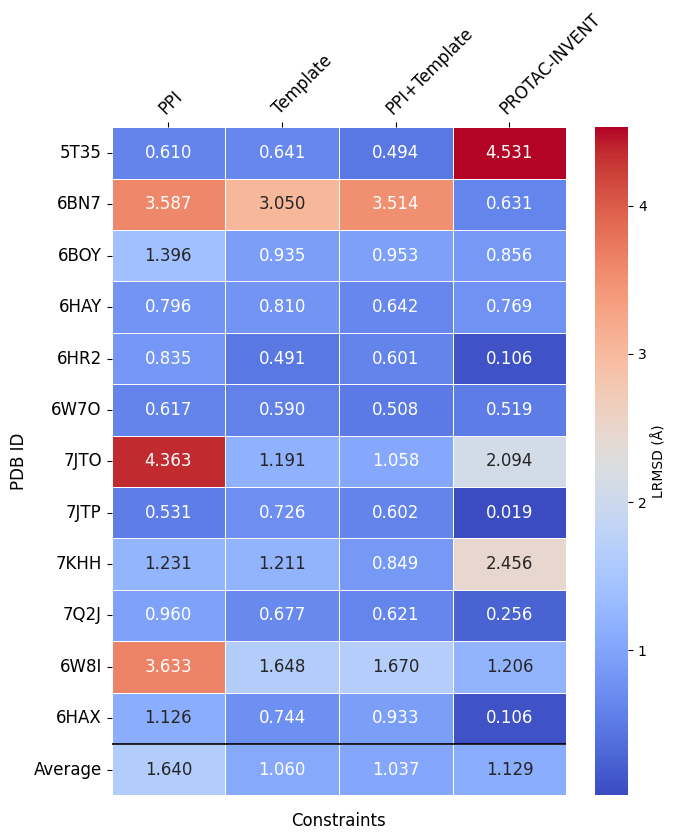

In [19]:
# LRMSD heatmap: LRMSD is the mean of the PL and EL values, 6ZHC left out.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

NDIGITS = 3
FONTSIZE = 12               # annotation font size inside the heatmap cells

dockq = pd.read_csv("pdb14_dockq.csv")
invent = pd.read_csv("PROTAC-INVENT-RMSD.csv")

dockq = dockq[dockq["pdbid"].str.lower() != "6zhc"].copy()
dockq["PDB ID"] = dockq["pdbid"].str.upper()

dockq["PPI"] = (dockq["ppi_PL_LRMSD"] + dockq["ppi_EL_LRMSD"]) / 2
dockq["Template"] = (dockq["tmp_PL_LRMSD"] + dockq["tmp_EL_LRMSD"]) / 2
dockq["PPI+Template"] = (dockq["ppi_tmp_PL_LRMSD"] + dockq["ppi_tmp_EL_LRMSD"]) / 2

invent = invent[["PDB ID", "RMSD"]].dropna(subset=["PDB ID"])
invent["PDB ID"] = invent["PDB ID"].str.upper()
invent = invent.rename(columns={"RMSD": "PROTAC-INVENT"})

cols = ["PPI", "Template", "PPI+Template", "PROTAC-INVENT"]
lrmsd = (
    dockq[["PDB ID"] + cols[:-1]]
    .merge(invent, on="PDB ID", how="left")
    .set_index("PDB ID")[cols]
).round(NDIGITS)

# last row holds the column averages
lrmsd.loc["Average"] = lrmsd.mean().round(NDIGITS)

print(lrmsd.to_string(float_format=f"%.{NDIGITS}f"))

fig, ax = plt.subplots(figsize=(7, 8.5))
sns.heatmap(
    lrmsd,
    annot=True,
    fmt=f".{NDIGITS}f",
    cmap="coolwarm",          # a low LRMSD is good, so blue means good
    linewidths=0.5,
    linecolor="white",
    annot_kws={"fontsize": FONTSIZE},
    ax=ax,
    cbar_kws={"label": "LRMSD (Å)"},
)

# tick labels stay on top, the axis title goes below the heatmap
ax.xaxis.tick_top()
plt.setp(ax.get_xticklabels(), rotation=45, ha="left", rotation_mode="anchor",
         fontsize=FONTSIZE)
ax.xaxis.set_label_position("bottom")
ax.set_xlabel("Constraints", labelpad=12, fontsize=FONTSIZE)

ax.set_ylabel("PDB ID", fontsize=FONTSIZE)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=FONTSIZE)
ax.axhline(len(lrmsd) - 1, color="black", linewidth=1.2)

plt.tight_layout()
plt.savefig('../../pics/pdb14_rmsd.png',dpi=600)
plt.show()

          PPI  Template  PPI+Template
PDB ID                               
5T35    0.955     0.925         0.960
6BN7    0.865     0.950         0.925
6BOY    0.845     0.916         0.919
6HAY    0.860     0.910         0.928
6HR2    0.929     0.939         0.939
6W7O    0.941     0.945         0.936
7JTO    0.491     0.882         0.875
7JTP    0.846     0.833         0.836
7KHH    0.959     0.973         0.975
7Q2J    0.893     0.802         0.865
6W8I    0.598     0.927         0.928
6HAX    0.880     0.923         0.904
Average 0.839     0.910         0.916


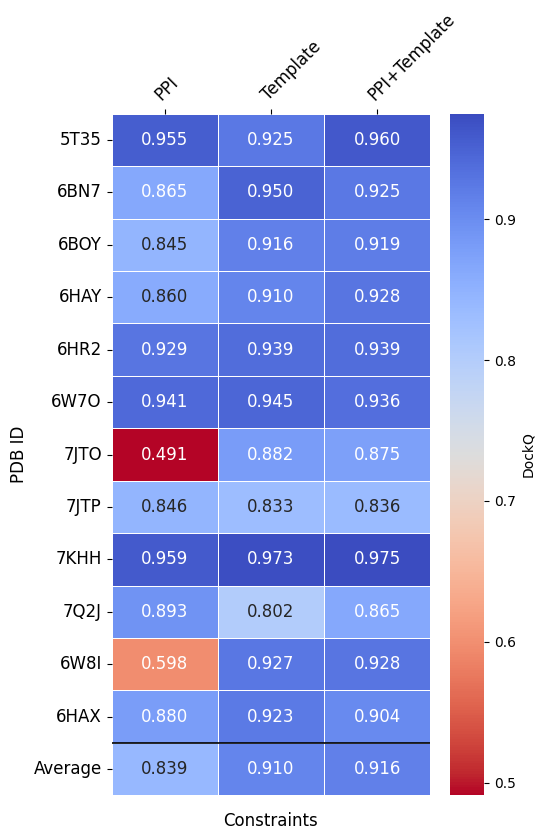

In [16]:
# DockQ heatmap of the same benchmark, 6ZHC left out.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

NDIGITS = 3
FONTSIZE = 12               # annotation font size inside the heatmap cells

dockq = pd.read_csv("pdb14_dockq.csv")

dockq = dockq[dockq["pdbid"].str.lower() != "6zhc"].copy()
dockq["PDB ID"] = dockq["pdbid"].str.upper()

dockq["PPI"] = dockq["ppi_PE_DockQ"]
dockq["Template"] = dockq["tmp_PE_DockQ"]
dockq["PPI+Template"] = dockq["ppi_tmp_PE_DockQ"]

cols = ["PPI", "Template", "PPI+Template"]
dockq = dockq.set_index("PDB ID")[cols].round(NDIGITS)

# last row holds the column averages
dockq.loc["Average"] = dockq.mean().round(NDIGITS)

print(dockq.to_string(float_format=f"%.{NDIGITS}f"))

fig, ax = plt.subplots(figsize=(5.5, 8.5))
sns.heatmap(
    dockq,
    annot=True,
    fmt=f".{NDIGITS}f",
    cmap="coolwarm_r",        # a high DockQ is good, so blue means good
    linewidths=0.5,
    linecolor="white",
    annot_kws={"fontsize": FONTSIZE},
    ax=ax,
    cbar_kws={"label": "DockQ"},
)

# tick labels stay on top, the axis title goes below the heatmap
ax.xaxis.tick_top()
plt.setp(ax.get_xticklabels(), rotation=45, ha="left", rotation_mode="anchor",
         fontsize=FONTSIZE)
ax.xaxis.set_label_position("bottom")
ax.set_xlabel("Constraints", labelpad=12, fontsize=FONTSIZE)

ax.set_ylabel("PDB ID", fontsize=FONTSIZE)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=FONTSIZE)
ax.axhline(len(dockq) - 1, color="black", linewidth=1.2)

plt.tight_layout()
plt.savefig('../../pics/pdb14_dock.png',dpi=600)
plt.show()